# zf-approx

A lean, standard-library-only Python implementation of the deterministic approximation
algorithm for the **zero forcing number** from

> {B. Cameron, J. Janssen, R. Mathew, Z. Zhang (2025) An approximation algorithm for zero forcing, *Discrete Applied Mathematics*, **383**, 227--242, https://www.sciencedirect.com/science/article/pii/S0166218X2500722X. 

Given a graph and a path decomposition of width `w`, the algorithm returns a zero forcing
set `S`, a fort packing `F`, and the forcing arcs `A`, with the guaranteed bound

    |S| ≤ (w + 1) · |F|.

Because `|F| ≤ Z(G) ≤ |S|`, the returned set is a `(w + 1)`-approximation of the zero
forcing number `Z(G)`; with an optimal decomposition (`w = pw(G)`) this is the paper's
pathwidth-based approximation ratio. The core trusts suitable inputs and contains no
validation; a thin outside layer checks them (connected graph; bags form a path
decomposition) and nicifies the decomposition before running the algorithm.

## Quickstart

    pip install networkx matplotlib   # only needed to build inputs and draw results

```python
import networkx as nx
import zf

G = nx.Graph()
G.add_edges_from([(1, 2), (2, 3), (3, 4), (1, 4), (2, 5), (3, 5)])  # the "house"
bags = [{1, 4}, {1, 3, 4}, {1, 2, 3}, {2, 3, 5}]   # a path decomposition; need not be nice

r = zf.zf_via_path_decomp(G, bags)
print(r.zf_set)   # (3, 4)
print(r.forts)    # (frozenset({1, 2, 3, 4}),)
print(r.arcs)     # ((1, 2), (2, 5), (4, 1))

In [1]:
import sys


import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import zf

%matplotlib inline


def report(r, bags):
    """Line-by-line results, with the guarantee bound aligned and checked."""
    w = max(map(len, bags)) - 1
    nS, nF = len(r.zf_set), len(r.forts)
    print(f"S        = {r.zf_set}")
    print(f"forts    = {[sorted(f) for f in r.forts]}")
    print(f"arcs     = {r.arcs}")
    print(f"|S|      = {nS}")
    print(f"w        = {w}")
    print(f"|F|      = {nF}")
    print(f"(w+1)|F| = {(w + 1) * nF}")
    print(f"|S| <= (w+1)|F| : {nS} <= {(w + 1) * nF}  "
          f"{'OK' if nS <= (w + 1) * nF else 'VIOLATED'}")


def present(G, pos, r):
    """One figure per case: S green, forcing arcs purple arrows.
    The explanation lives in the legend (outside the axes, never over nodes)."""
    S = set(r.zf_set)
    fig, ax = plt.subplots(figsize=(7.6, 4.6 if G.number_of_edges() else 2.8))
    colors = ["#2ca02c" if v in S else "#cfcfcf" for v in G.nodes]
    nx.draw_networkx(G, pos, ax=ax, node_color=colors, node_size=750,
                     font_weight="bold", edge_color="#888888")
    if r.arcs:
        nx.draw_networkx_edges(G, pos, edgelist=list(r.arcs), ax=ax,
                               edge_color="#7c3aed", width=2.5, arrows=True,
                               arrowstyle="-|>", arrowsize=22,
                               connectionstyle="arc3,rad=0.12",
                               min_source_margin=20, min_target_margin=20)
        nx.draw_networkx_nodes(G, pos, nodelist=sorted(S), ax=ax,
                               node_color="#2ca02c", node_size=750)
        nx.draw_networkx_labels(G, pos, ax=ax, font_weight="bold")
    ax.legend(handles=[Patch(color="#2ca02c", label="S (zero forcing set)"),
                       Line2D([0], [0], color="#7c3aed", lw=2.5, marker=">",
                              markersize=7, label="forcing arcs A"),
                       Patch(color="#cfcfcf", label="other vertices")],
              loc="center left", bbox_to_anchor=(1.0, 0.5))
    ax.margins(0.15)
    fig.tight_layout()
    plt.show()

S        = (3, 4)
forts    = [[1, 2, 3, 4]]
arcs     = ((1, 2), (2, 5), (4, 1))
|S|      = 2
w        = 2
|F|      = 1
(w+1)|F| = 3
|S| <= (w+1)|F| : 2 <= 3  OK


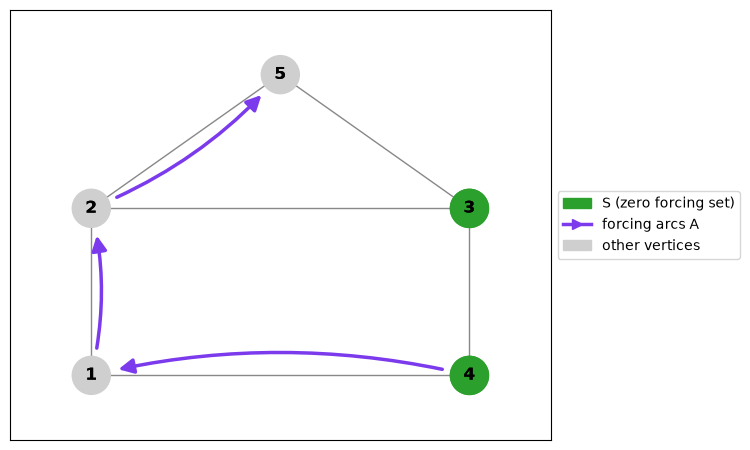

In [2]:
G = nx.Graph()
G.add_nodes_from([1, 2, 3, 4, 5])
G.add_edges_from([(1, 2), (2, 3), (3, 4), (1, 4),   # the square
                  (2, 5), (3, 5)])                  # the roof
pos = {1: (0, 0), 2: (0, 1), 3: (1, 1), 4: (1, 0), 5: (0.5, 1.8)}
bags = [{1, 4}, {1, 3, 4}, {1, 2, 3}, {2, 3, 5}]    # width 2, not nice

r = zf.zf_via_path_decomp(G, bags)
report(r, bags)          # <- replaces the two print lines and the w = ... line
present(G, pos, r)

S = (0, 4) | forts = [[0, 1, 2, 3]] | arcs = ((0, 1), (1, 2), (2, 3))
guarantee: |S| = 2 <= (2+1)*1 = 3


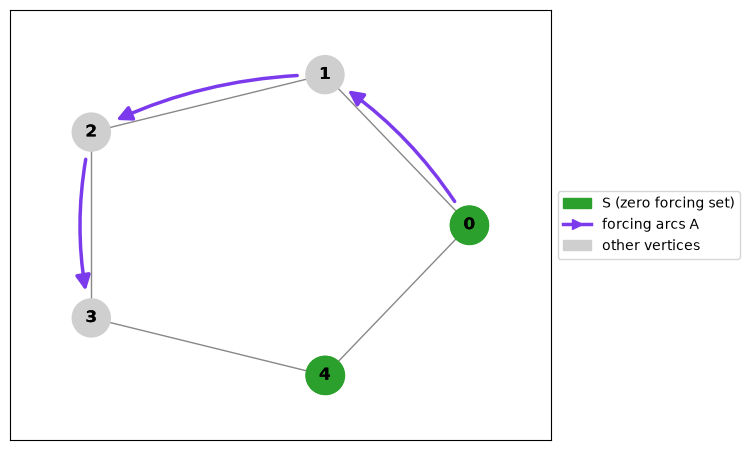

In [3]:
G = nx.cycle_graph(5)                               # nodes 0..4
pos = nx.circular_layout(G)
bags = [{0, 1}, {0, 1, 2}, {0, 2, 3}, {0, 3, 4}]    # width 2, not nice

r = zf.zf_via_path_decomp(G, bags)
print("S =", r.zf_set, "| forts =", [sorted(f) for f in r.forts], "| arcs =", r.arcs)
w = max(map(len, bags)) - 1
print(f"guarantee: |S| = {len(r.zf_set)} <= ({w}+1)*{len(r.forts)} = {(w+1)*len(r.forts)}")
present(G, pos, r)


In [4]:
"""
Input contract: 
 The outside layer requires a **connected** graph and bags that form a path
 decomposition (D1 edge coverage, D2 contiguity, every vertex covered). The cell
 below deliberately violates connectedness: the call halts with `ValueError`.
 The core itself trusts its inputs and raises nothing.
"""

G = nx.Graph()
G.add_nodes_from(["a", "b"])
pos = {"a": (0, 0), "b": (1, 0)}
bags = [{"a"}, {"b"}]                               # width 0; each isolate its own fort

r = zf.zf_via_path_decomp(G, bags)
report(r, bags)          # <- replaces the two print lines and the w = ... line
present(G, pos, r)

ValueError: graph is not connected; the outside API requires a connected graph (the paper's assumption); the core itself trusts inputs

S        = (1, 3, 6, 10, 11)
forts    = [[1, 2], [4, 5, 6, 7], [10, 11]]
arcs     = ((1, 2), (3, 5), (6, 7), (8, 4), (9, 8), (10, 9))
|S|      = 5
w        = 2
|F|      = 3
(w+1)|F| = 9
|S| <= (w+1)|F| : 5 <= 9  OK


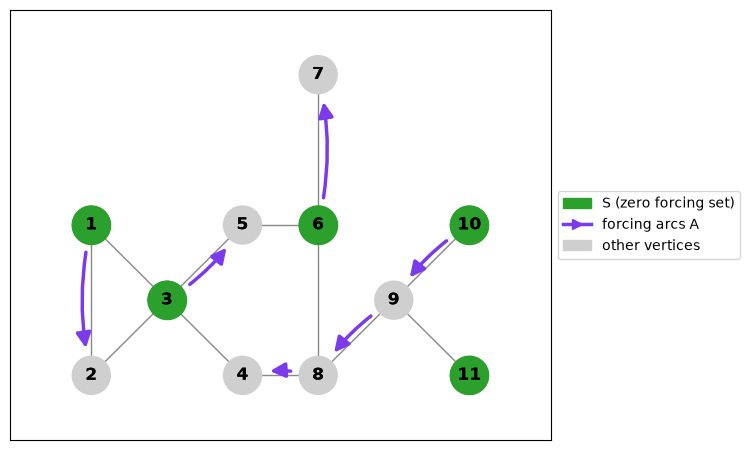

In [5]:

H = nx.Graph()

E = [(1,2), (2,3), (1,3),
    (3,5), (5,6), (6,8), (4,8),   (3,4),
    (6,7), (8,9), (9, 10), (9,11)]
H.add_edges_from(E)
bags = [
    [],
    [1],
    [1, 2],
    [1, 2, 3],
    [2, 3],
    [3],
    [3, 4],
    [3, 4, 5],
    [4, 5],
    [4, 5, 6],
    [4, 6],
    [4, 6, 7],
    [4, 6],
    [4, 6, 8],
    [6, 8],
    [8],
    [8, 9],
    [9],
    [9, 10],
    [9, 10, 11],
    [10, 11],
    [11],
    []
]
pos = {1: (0, 2), 2: (0, 1), 3: (1, 1.5),
       4: (2, 1), 5: (2, 2),
       6: (3, 2), 7: (3, 3), 8: (3, 1),
       9: (4, 1.5), 10: (5, 2), 11: (5, 1)}

r = zf.zf_via_path_decomp(H, bags)
report(r, bags)          # <- replaces the two print lines and the w = ... line
present(H, pos, r)